In [ ]:
import torch  
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix,roc_auc_score,classification_report)
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data_free = np.load("clean_final_spec.npy")
spectra_free = data_free[:,:52]
label_free = np.zeros(len(spectra_free)) #0-free chem

In [3]:
spectra_eq = np.load('eq_chemistry_spectra.npy')
label_eq   = np.ones(len(spectra_eq))

In [4]:
n_free = len(spectra_free)      # 98,495
n_eq   = len(spectra_eq)        # 113,176

print(f"Free chemistry:        {n_free}")
print(f"Equilibrium chemistry: {n_eq}")

Free chemistry:        98495
Equilibrium chemistry: 113176


In [5]:
n_use = min(n_free, n_eq)
print(f"Using {n_use} from each class")

Using 98495 from each class


In [9]:
np.random.seed(42)
eq_idx = np.random.choice(n_eq, n_use, replace=False)
spectra_eq_balanced = spectra_eq[eq_idx]
label_eq = label_eq[eq_idx]
print(f"\nFinal dataset:")
print(f"Free chemistry:        {n_use} spectra — label 0")
print(f"Equilibrium chemistry: {n_use} spectra — label 1")
print(f"Total:                 {n_use*2} spectra")


Final dataset:
Free chemistry:        98495 spectra — label 0
Equilibrium chemistry: 98495 spectra — label 1
Total:                 196990 spectra


In [10]:
spectra_free_norm = spectra_free / spectra_free.mean(axis=1,keepdims=True)
spectra_eq_norm   = spectra_eq_balanced  / spectra_eq_balanced.mean(axis=1,keepdims=True)

print(f"Shape of normalised Free chemistry spectra: {spectra_free_norm.shape}")
print(f"Shape of normalised Equilibrium chemistry spectra: {spectra_eq_norm.shape}")

Shape of normalised Free chemistry spectra: (98495, 52)
Shape of normalised Equilibrium chemistry spectra: (98495, 52)


In [11]:
X = np.vstack([spectra_free_norm, spectra_eq_norm]).astype(np.float32)
y = np.concatenate([label_free, label_eq]).astype(np.float32)
print(f"Total dataset: {X.shape}")
print(f"Class balance: {y.mean():.3f}")

Total dataset: (196990, 52)
Class balance: 0.500


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, stratify=y_test, random_state=42)
print(f"Train: {X_train.shape}")
print(f"Val:   {X_val.shape}")
print(f"Test:  {X_test.shape}")

Train: (157592, 52)
Val:   (19699, 52)
Test:  (19699, 52)


In [14]:
def to_tensor(X,y):
  return(torch.tensor(X).unsqueeze(1),torch.tensor(y).unsqueeze(1))

X_train_t,y_train_t = to_tensor(X_train,y_train)
X_test_t,y_test_t = to_tensor(X_test,y_test)
X_val_t,y_val_t = to_tensor(X_val,y_val)

In [15]:
train_loader = DataLoader(TensorDataset(X_train_t,y_train_t),batch_size=256,shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t),batch_size=256)

In [17]:
class SpectralChemistryClassifier(nn.Module):
  def __init__(self):
    super().__init__()

    self.conv_block = nn.Sequential(
        #block 1 (52 -> 26)
        nn.Conv1d(1,32,kernel_size=5,padding=2),
        nn.ReLU(),
        nn.MaxPool1d(2),

        #block 2 (26 -> 13)
        nn.Conv1d(32,64,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.MaxPool1d(2),

        #block 3 (13 -> 6)
        nn.Conv1d(64,128,kernel_size=3,padding=1),
        nn.ReLU()
    )

    self.global_pool = nn.AdaptiveAvgPool1d(1)

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(128,64),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(64,1),
        nn.Sigmoid()
    )

  def forward(self,x):
    x = self.conv_block(x)
    x = self.global_pool(x)
    x = self.classifier(x)
    return x

model_clf = SpectralChemistryClassifier()
print(model_clf)
total_params = sum(p.numel() for p in model_clf.parameters())
print(f"\nTotal parameters: {total_params:,}")

SpectralChemistryClassifier(
  (conv_block): Sequential(
    (0): Conv1d(1, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (7): ReLU()
  )
  (global_pool): AdaptiveAvgPool1d(output_size=1)
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=1, bias=True)
    (5): Sigmoid()
  )
)

Total parameters: 39,425


# Training

In [21]:
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model_clf.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

n_epochs = 50
train_losses, val_losses, val_accs = [], [], []
best_val_loss = float('inf')

In [22]:
from torch.nn.modules import loss
for epoch in range(n_epochs):
  # train
  model_clf.train()
  batch_losses = []
  for X_batch,y_batch in train_loader:
    optimizer.zero_grad()
    pred = model_clf(X_batch)
    loss = criterion(pred,y_batch)
    loss.backward()
    optimizer.step()
    batch_losses.append(loss.item())

  train_loss = np.mean(batch_losses)
  train_losses.append(train_loss)

  # val
  model_clf.eval()
  with torch.no_grad():
    val_pred = model_clf(X_val_t)
    val_loss = criterion(val_pred,y_val_t).item()
    val_acc = ((val_pred > 0.5).float() == y_val_t).float().mean().item()

  val_losses.append(val_loss)
  val_accs.append(val_acc)
  scheduler.step(val_loss)

  # save the best
  if val_loss < best_val_loss:
    best_val_loss = val_loss
    torch.save(model_clf.state_dict(), 'best_classifier.pth')

  if epoch % 5 == 0:
    print(f"Epoch {epoch:3d} | "f"Train Loss: {train_loss:.4f} | "f"Val Loss: {val_loss:.4f} | "f"Val Acc: {val_acc:.4f}")


Epoch   0 | Train Loss: 0.6932 | Val Loss: 0.6931 | Val Acc: 0.5001
Epoch   5 | Train Loss: 0.2702 | Val Loss: 0.2258 | Val Acc: 0.9128
Epoch  10 | Train Loss: 0.2312 | Val Loss: 0.1783 | Val Acc: 0.9146
Epoch  15 | Train Loss: 0.2167 | Val Loss: 0.1361 | Val Acc: 0.9407
Epoch  20 | Train Loss: 0.1331 | Val Loss: 0.1517 | Val Acc: 0.9207
Epoch  25 | Train Loss: 0.1910 | Val Loss: 0.1122 | Val Acc: 0.9593
Epoch  30 | Train Loss: 0.1060 | Val Loss: 0.0924 | Val Acc: 0.9655
Epoch  35 | Train Loss: 0.0923 | Val Loss: 0.0894 | Val Acc: 0.9738
Epoch  40 | Train Loss: 0.0868 | Val Loss: 0.1206 | Val Acc: 0.9400
Epoch  45 | Train Loss: 0.0836 | Val Loss: 0.0745 | Val Acc: 0.9706


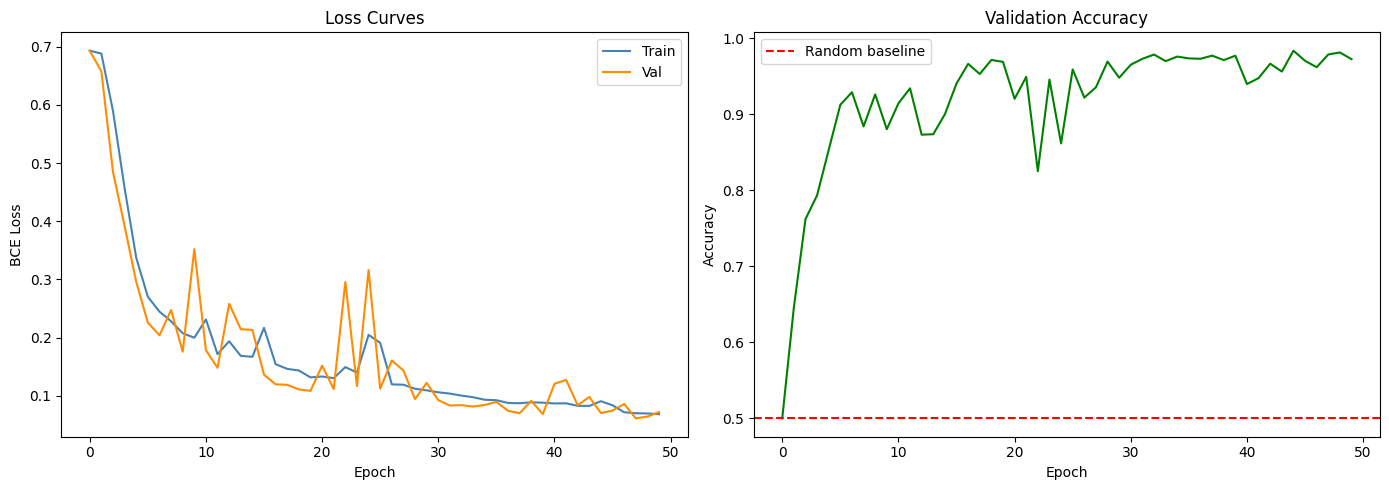

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label='Train', color='steelblue')
axes[0].plot(val_losses,   label='Val',   color='darkorange')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE Loss')
axes[0].set_title('Loss Curves')
axes[0].legend()

axes[1].plot(val_accs, color='green')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Validation Accuracy')
axes[1].axhline(0.5, color='red', linestyle='--', label='Random baseline')
axes[1].legend()

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

# Testing

In [31]:
model_clf.load_state_dict(torch.load('best_classifier.pth'))
model_clf.eval()

with torch.no_grad():
  test_pred = model_clf(X_test_t).numpy().flatten()
  test_labels = (test_pred > 0.5).astype(float)

In [32]:
y_test_np = y_test if isinstance(y_test, np.ndarray) else y_test.numpy()
y_test_np = y_test_np.astype(float)
auc = roc_auc_score(y_test, test_pred)
print(f"Test Accuracy : {(test_labels == y_test).mean():.4f}")
print(f"ROC-AUC Score : {auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, test_labels,target_names=['Free', 'Equilibrium']))

Test Accuracy : 0.9790
ROC-AUC Score : 0.9976

Classification Report:
              precision    recall  f1-score   support

        Free       1.00      0.96      0.98      9850
 Equilibrium       0.96      1.00      0.98      9849

    accuracy                           0.98     19699
   macro avg       0.98      0.98      0.98     19699
weighted avg       0.98      0.98      0.98     19699



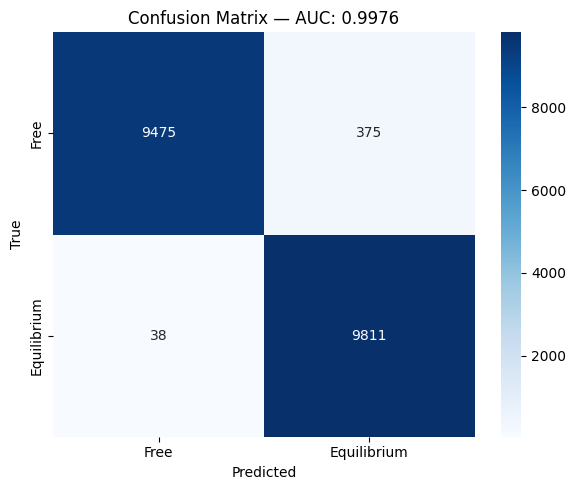

In [33]:
cm = confusion_matrix(y_test, test_labels)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',xticklabels=['Free', 'Equilibrium'],yticklabels=['Free', 'Equilibrium'])
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title(f'Confusion Matrix - AUC: {auc:.4f}')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()